# Этап 1. Знакомство с данными и аудит качества

## Подключение к БД

In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# добавление папки src в места поиска модулей
sys.path.append(str(Path.cwd().parent / 'src'))

from db import query, execute


## Проверка подключения к базе и вывод названий всех таблиц в БД

In [2]:
query('SELECT name FROM sqlite_master WHERE type = "table"')

,name
0,users
1,devices
2,app_releases
3,screens
4,sessions
5,screen_views
6,events
7,orders
8,ab_assignments


---

# <u>Просмотр всех таблиц и столбцов в них для планирования анализа данных</u>


In [3]:
query('SELECT'
      ' sm.name AS table_name, '
      ' t_info.name AS column_name, '
      ' t_info.type AS column_type '
      'FROM sqlite_master sm '
      'JOIN pragma_table_info(sm.name) t_info '
      'WHERE sm.type = "table" '
      'ORDER BY sm.name, t_info.cid;')

,table_name,column_name,column_type
0,ab_assignments,user_id,INTEGER
1,ab_assignments,experiment,TEXT
2,ab_assignments,variant,TEXT
3,ab_assignments,assigned_at,TEXT
4,app_releases,platform,TEXT
5,app_releases,app_version,TEXT
6,app_releases,released_at,TEXT
7,app_releases,notes,TEXT
8,devices,device_id,TEXT
9,devices,user_id,INTEGER


---

## <u>1.1 Объем и диапазон дат</u>

In [4]:
query('''
SELECT 'sessions start' AS tbl, COUNT(*) AS rows,
MIN(started_at) AS min_date, MAX(started_at) AS max_date
FROM sessions
UNION ALL
SELECT 'sessions end', COUNT(*),
MIN(ended_at), MAX(ended_at)
FROM sessions
UNION ALL
SELECT 'orders create', COUNT(*),
MIN(created_at), MAX(created_at)
FROM orders
UNION ALL
SELECT 'screen_views enter', COUNT(*),
MIN(entered_at), MAX(entered_at)
FROM screen_views
UNION ALL
SELECT 'users registrate', COUNT(*),
MIN(registered_at), MAX(registered_at)
FROM users
UNION ALL
SELECT 'devices first seen', COUNT(*),
MIN(first_seen_at), MAX(first_seen_at)
FROM devices
UNION ALL
SELECT 'app_releases release', COUNT(*),
MIN(released_at), MAX(released_at)
FROM app_releases
UNION ALL
SELECT 'ab_assignments assign', COUNT(*),
MIN(assigned_at), MAX(assigned_at)
FROM ab_assignments
UNION ALL
SELECT 'events client', COUNT(*),
MIN(client_ts), MAX(client_ts)
FROM events
UNION ALL
SELECT 'events server', COUNT(*),
MIN(server_ts), MAX(server_ts)
FROM events
UNION ALL
SELECT 'screens info', COUNT(*),
NULL, NULL
FROM screens;
''')

,tbl,rows,min_date,max_date
0,sessions start,49191,2026-05-31 21:40:05,2026-08-31 18:48:39
1,sessions end,49191,2026-05-31 21:40:55,2026-08-31 18:56:54
2,orders create,21954,2026-05-31 23:20:55,2026-08-31 18:50:38
3,screen_views enter,286078,2026-05-31 21:40:05,2026-08-31 18:56:48
4,users registrate,9006,2025-01-01 07:08:27,2026-08-30 18:40:34
5,devices first seen,9006,2025-01-01 07:08:27,2026-08-30 18:40:34
6,app_releases release,9,2026-05-20,2026-08-13
7,ab_assignments assign,9031,2026-06-30 21:01:00,2026-08-31 18:36:19
8,events client,270273,2025-05-04 08:33:10,2027-07-11 03:44:33
9,events server,270273,2026-05-31 21:40:05,2026-08-31 23:39:16


#### По данной таблице можно увидеть, что:
1. Самое позднее время во всех таблицах это 18:56 и оно почти везде одинаковое, значит можно сделать вывод, что в БД время отличается от Узбекистана (UTC+5), если исправить, то время увеличится на 5 часов - это и будет граница периода по ТЗ
2. По объему данных:
    1)  ~ 9 000 пользователей - верно
    2)  ~ 49 000 сессий - верно
    3)  ~ 286 000 просмотров экранов - верно
    4)  ~ 270 000 событий - верно
    5)  ~ 22 000 заказов - верно
3. У таблицы  app_releases формат даты отличен от остальных. Требует внимания!
4. В таблицах users и devices полное совпадение минимумов и максимумов. То есть 1 пользователь = 1 устройство. Нужно потом разобраться почему так? и почему момент регистрации совпадает с первым подключением устройства до секунды?
5. events: Почему у события на стороне Клиента не совпадают с датами событий на стороне Сервера? Почему события сервера вписываются в диапазон по ТЗ, а события на стороне Клиента имеют больший разброс по датам (количество строк у них одинаковое) и максимум уходит в будущее? Может ли проблема быть на стороне Клиента?

### Время на стороне Клиента ненадежно, поэтому для дальнейшего анализа буду использовать время Сервера. Со временем на стороне Клиента разберусь в следующих шагах

---


## <u>1.2 Поиск пропусков в данных по ключевым полям</u>

#### Вывод всех полей, где есть пропуски и их процентное соотношение

In [5]:
query('''
WITH nulls AS (
      SELECT 'users' AS table_name, 'city' AS column_name,
             ROUND(AVG(city IS NULL) * 100, 1) AS null_pct
      FROM users
      UNION ALL
      SELECT 'users', 'registered_at',
             ROUND(AVG(registered_at IS NULL) * 100, 1)
      FROM users
      UNION ALL
      SELECT 'users', 'birth_year',
             ROUND(AVG(birth_year IS NULL) * 100, 1)
      FROM users
      UNION ALL
      SELECT 'users', 'acquisition_channel',
             ROUND(AVG(acquisition_channel IS NULL) * 100, 1)
      FROM users
      UNION ALL
      SELECT 'devices', 'user_id',
             ROUND(AVG(user_id IS NULL) * 100, 1)
      FROM devices
      UNION ALL
      SELECT 'devices', 'platform',
             ROUND(AVG(platform IS NULL) * 100, 1)
      FROM devices
      UNION ALL
      SELECT 'devices', 'device_model',
             ROUND(AVG(device_model IS NULL) * 100, 1)
      FROM devices
      UNION ALL
      SELECT 'devices', 'os_version',
             ROUND(AVG(os_version IS NULL) * 100, 1)
      FROM devices
      UNION ALL
      SELECT 'sessions', 'user_id',
             ROUND(AVG(user_id IS NULL) * 100, 1)
      FROM sessions
      UNION ALL
      SELECT 'sessions', 'device_id',
             ROUND(AVG(device_id IS NULL) * 100, 1)
      FROM sessions
      UNION ALL
      SELECT 'sessions', 'started_at',
             ROUND(AVG(started_at IS NULL) * 100, 1)
      FROM sessions
      UNION ALL
      SELECT 'sessions', 'ended_at',
             ROUND(AVG(ended_at IS NULL) * 100, 1)
      FROM sessions
      UNION ALL
      SELECT 'sessions', 'app_version',
             ROUND(AVG(app_version IS NULL) * 100, 1)
      FROM sessions
      UNION ALL
      SELECT 'sessions', 'network_type',
             ROUND(AVG(network_type IS NULL) * 100, 1)
      FROM sessions
      UNION ALL
      SELECT 'screen_views', 'session_id',
             ROUND(AVG(session_id IS NULL) * 100, 1)
      FROM screen_views
      UNION ALL
      SELECT 'screen_views', 'screen_name',
             ROUND(AVG(screen_name IS NULL) * 100, 1)
      FROM screen_views
      UNION ALL
      SELECT 'screen_views', 'entered_at',
             ROUND(AVG(entered_at IS NULL) * 100, 1)
      FROM screen_views
      UNION ALL
      SELECT 'screen_views', 'duration_ms',
             ROUND(AVG(duration_ms IS NULL) * 100, 1)
      FROM screen_views
      UNION ALL
      SELECT 'events', 'session_id',
             ROUND(AVG(session_id IS NULL) * 100, 1)
      FROM events
      UNION ALL
      SELECT 'events', 'user_id',
             ROUND(AVG(user_id IS NULL) * 100, 1)
      FROM events
      UNION ALL
      SELECT 'events', 'client_ts',
             ROUND(AVG(client_ts IS NULL) * 100, 1)
      FROM events
      UNION ALL
      SELECT 'events', 'server_ts',
             ROUND(AVG(server_ts IS NULL) * 100, 1)
      FROM events
      UNION ALL
      SELECT 'events', 'event_name',
             ROUND(AVG(event_name IS NULL) * 100, 1)
      FROM events
      UNION ALL
      SELECT 'events', 'screen_name',
             ROUND(AVG(screen_name IS NULL) * 100, 1)
      FROM events
      UNION ALL
      SELECT 'events', 'event_params',
             ROUND(AVG(event_params IS NULL) * 100, 1)
      FROM events
      UNION ALL
      SELECT 'orders', 'service',
             ROUND(AVG(service IS NULL) * 100, 1)
      FROM orders
      UNION ALL
      SELECT 'orders', 'tariff',
             ROUND(AVG(tariff IS NULL) * 100, 1)
      FROM orders
      UNION ALL
      SELECT 'orders', 'status',
             ROUND(AVG(status IS NULL) * 100, 1)
      FROM orders
      UNION ALL
      SELECT 'orders', 'price_uzs',
             ROUND(AVG(price_uzs IS NULL) * 100, 1)
      FROM orders
      UNION ALL
      SELECT 'orders', 'wait_time_sec',
             ROUND(AVG(wait_time_sec IS NULL) * 100, 1)
      FROM orders
      UNION ALL
      SELECT 'orders', 'rating',
             ROUND(AVG(rating IS NULL) * 100, 1)
      FROM orders
      UNION ALL
      SELECT 'orders', 'promo_applied',
             ROUND(AVG(promo_applied IS NULL) * 100, 1)
      FROM orders
      UNION ALL
      SELECT 'ab_assignments', 'variant',
             ROUND(AVG(variant IS NULL) * 100, 1)
      FROM ab_assignments
      UNION ALL
      SELECT 'ab_assignments', 'assigned_at',
             ROUND(AVG(assigned_at IS NULL) * 100, 1)
      FROM ab_assignments
      UNION ALL
      SELECT 'app_releases', 'released_at',
             ROUND(AVG(released_at IS NULL) * 100, 1)
      FROM app_releases
      UNION ALL
      SELECT 'app_releases', 'notes',
             ROUND(AVG(notes IS NULL) * 100, 1)
      FROM app_releases
      UNION ALL
      SELECT 'screens', 'service',
             ROUND(AVG(service IS NULL) * 100, 1)
      FROM screens
      UNION ALL
      SELECT 'screens', 'description',
             ROUND(AVG(description IS NULL) * 100, 1)
      FROM screens
)
SELECT table_name, column_name, null_pct
FROM nulls
WHERE null_pct > 0
ORDER BY table_name, null_pct DESC;
''')

,table_name,column_name,null_pct
0,events,event_params,21.4
1,events,screen_name,19.5
2,events,user_id,3.2
3,orders,rating,64.0
4,orders,tariff,22.7
5,orders,wait_time_sec,22.7
6,orders,price_uzs,19.0
7,sessions,ended_at,0.9
8,users,birth_year,4.8


### Результат: из 38 проверенных полей пропуски есть только в 9
---

### <u>Анализ пропусков по таблице `events`</u>

In [6]:
query('''
WITH events_params_null AS (
      SELECT ev.event_name AS event_name,
            COUNT(*) AS event_count,
            ROUND(AVG(ev.event_params IS NULL) * 100, 1) AS params_null_pct
      FROM events ev
      GROUP BY ev.event_name
)
SELECT event_name, event_count, params_null_pct
FROM events_params_null
WHERE params_null_pct > 0
ORDER BY params_null_pct DESC;
''')

,event_name,event_count,params_null_pct
0,app_background,49315,100.0
1,favorite_address_add,262,100.0
2,favorite_address_click,4182,100.0
3,no_cars_found,1362,100.0
4,onboarding_skip,2653,100.0


#### Пропуски только в 5 видах событий и у каждого из них в 100 % случаев, у остальных - 0 %.
делаю вывод, что это норма.

In [7]:
query('''
WITH events_screen_null AS (
      SELECT ev.event_name AS event_name,
            COUNT(*) AS event_count,
            ROUND(AVG(ev.screen_name IS NULL) * 100, 1) AS screen_null_pct
      FROM events ev
      GROUP BY ev.event_name
)
SELECT event_name, event_count, screen_null_pct
FROM events_screen_null
WHERE screen_null_pct > 0
ORDER BY screen_null_pct DESC;
''')

,event_name,event_count,screen_null_pct
0,app_background,49315,100.0
1,push_open,3493,100.0


#### Пропуски только у системных событий:
   1. `app_background` - сворачивание приложения
   2. `push_open` - открытие из push уведомления
происходят вне какого-либо определенного экрана. Норма
---

### <u>Анализ пропусков по таблице `orders`</u>

In [8]:
query('''
SELECT o.service,
       o.status,
       COUNT(*) AS orders_cnt,
       ROUND(AVG(o.tariff IS NULL) * 100, 1)        AS tariff_null_pct,
       ROUND(AVG(o.wait_time_sec IS NULL) * 100, 1) AS wait_null_pct,
       ROUND(AVG(o.rating IS NULL) * 100, 1)        AS rating_null_pct
FROM orders AS o
GROUP BY o.service, o.status
ORDER BY o.service, o.status;
''')

,service,status,orders_cnt,tariff_null_pct,wait_null_pct,rating_null_pct
0,food,cancelled_restaurant,136,100.0,100.0,100.0
1,food,cancelled_user,427,100.0,100.0,100.0
2,food,completed,3045,100.0,100.0,100.0
3,scooter,completed,1377,100.0,100.0,100.0
4,taxi,cancelled_driver,513,0.0,0.0,100.0
5,taxi,cancelled_user,1749,0.0,0.0,100.0
6,taxi,completed,13359,0.0,0.0,40.9
7,taxi,no_cars,1348,0.0,0.0,100.0


#### По этой таблице видно, что пропуски объяснимы:
1. у еды и самокатов нет тарифа, время ожидания и оценки поездки
2. у такси поля тариф и время ожидания заполнены на 100 %
3. у отменных заказов или `no_cars` нет рейтинга - норма
4. среди выполненных заказов 40,9% неоцененных поездок - похоже на правду
---

### <u>Анализ оставшихся пропусков</u>

In [9]:
query('''
SELECT
      (SELECT ROUND(AVG(birth_year IS NULL) * 100, 1) FROM users)  AS user_birth_year_null,
      (SELECT ROUND(AVG(ended_at IS NULL) * 100, 1) FROM sessions) AS sessions_ended_at_null,
      (SELECT ROUND(AVG(user_id IS NULL) * 100, 1) FROM events)    AS events_user_id_null,
      (SELECT ROUND(AVG(price_uzs IS NULL) * 100, 1) FROM orders)  AS orders_price_uzs_null,
      (SELECT ROUND(AVG(price_uzs IS NULL) * 100, 1) FROM orders WHERE status = 'completed') AS completed_price_uzs_null;
''')

,user_birth_year_null,sessions_ended_at_null,events_user_id_null,orders_price_uzs_null,completed_price_uzs_null
0,4.8,0.9,3.2,19.0,0.0


#### По пропускам из таблицы видно, что:
   1. Есть 4,8 % пропусков в поле `users.birth_year`. Это значит, что пользователь не указал дату рождения, значит нужно исключать из подсчета возраста;
   2. Есть 0,9 % пропусков в `sessions.ended_at` - Сигнал, что сессия оборвалась. Проверить на этапе стабильности;
   3. Есть 3,2 % пропусков в `events.user_id` - это нормально, так как события до входа в аккаунт анонимны;
   4. Есть 19 % пропусков в `orders.price_uzs` - это нормально, так как у выполненных заказов `completed_price_uzs` пропусков 0 % - цены нет только у незавершенных заказов
---

## По результатам шага 1.2 обнаружен 1 сигнал в поле `sessions.ended_at` - обрыв сессии

#### Рассмотреть на этапе стабильности
---

## <u>1.3 Связи между таблицами</u>

In [10]:
query('''
-- использую LEFT JOIN, так как он сохраняет все строки левой таблицы,
-- если пары нет - будет NULL
SELECT
      -- заказы без сессии:
      (SELECT COUNT(*)
      FROM orders o
      LEFT JOIN sessions s ON s.session_id = o.session_id
      WHERE s.session_id IS NULL) AS orders_without_sessions,
      -- сессии без пользователя:
      (SELECT COUNT(*)
      FROM sessions s
      LEFT JOIN users u ON u.user_id = s.user_id
      WHERE u.user_id IS NULL) AS sessions_without_user,
      -- события без сессии:
      (SELECT COUNT(*)
      FROM events e
      LEFT JOIN sessions s ON s.session_id = e.session_id
      WHERE s.session_id IS NULL) AS events_without_sessions,
      -- просмотры экранов без сессии:
      (SELECT COUNT(*)
      FROM screen_views sv
      LEFT JOIN sessions s ON s.session_id = sv.session_id
      WHERE s.session_id IS NULL) AS screen_views_without_sessions,
      -- пользователи без устройств
      (SELECT COUNT(*)
      FROM users u
      LEFT JOIN devices d ON d.user_id = u.user_id
      WHERE d.user_id IS NULL) AS users_without_devices;
''')

,orders_without_sessions,sessions_without_user,events_without_sessions,screen_views_without_sessions,users_without_devices
0,0,0,0,0,0


#### Связи между таблицами проверены:
1. заказы -- сессии
2. сессии -- пользователи
3. события -- сессии
4. просмотры экранов -- сессии
5. пользователи -- устройства

#### Сирот нет ни в одной паре таблиц. + выяснила, что 1 пользователь = 1 устройство
---

## <u>1.4 Дубликаты событий</u>
###### Зачем? Телефон отправляет событие на сервер. Если ответ не пришел (плохая связь), то телефон отправит его еще раз и получится дубликат записи в событиях

In [11]:
query('''
SELECT
       COUNT(*) AS dup_groups,
       SUM(n - 1) AS extra_rows,
       ROUND(100.0 * SUM(n - 1) / (SELECT COUNT(*) FROM events), 2) AS extra_pct
FROM (
      SELECT event_name, COUNT(*) AS n
      FROM events
      GROUP BY session_id, event_name, client_ts, COALESCE(event_params, '')
      HAVING COUNT(*) > 1
      )
''')

,dup_groups,extra_rows,extra_pct
0,3329,3331,1.23


#### Получилась 3 331 лишняя строка - 1.23 % событий

In [12]:
query('''
SELECT d.event_name,
       COUNT(*) AS dup_groups,
       SUM(n - 1) AS extra_rows,
       ROUND(100.0 * SUM(n - 1) / (SELECT COUNT(*) FROM events), 2) AS extra_pct
FROM (
      SELECT event_name, COUNT(*) AS n
      FROM events
      GROUP BY session_id, event_name, client_ts, COALESCE(event_params, '')
      HAVING COUNT(*) > 1
      ) AS d
GROUP BY d.event_name
ORDER BY extra_rows DESC;
''')

,event_name,dup_groups,extra_rows,extra_pct
0,search_address,749,751,0.28
1,app_open,588,588,0.22
2,app_background,580,580,0.21
3,add_to_cart,336,336,0.12
4,order_create,286,286,0.11
5,select_tariff,254,254,0.09
6,rate_ride,100,100,0.04
7,login_success,65,65,0.02
8,favorite_address_click,64,64,0.02
9,search_restaurant,62,62,0.02


#### Сверка с таблицей `orders`:

* событий `orders.order_create` в шаге 1.2 было **22 240**;
* дублей `orders.order_create` здесь **286**;
* **22 240 − 286 = 21 954**, ровно столько строк в таблице `orders` (шаг 1.1).

После удаления дублей события сходятся с заказами до штуки. Значит:

* Дубли - это повторные отправки;
* Таблица `orders` надежна.
---

## <u>1.5 Время телефона против времени сервера</u>
###### Зачем? На шаге 1.1 обнаружено, что `client_ts` уходит в 2027 год. Теперь нужно понять у скольких устройств сбиты часы и насколько сбиты?

In [13]:
query('''
-- julianday() - превращает дату в число дней
SELECT device_id,
       AVG(julianday(server_ts) - julianday(client_ts)) AS avg_diff_days
FROM events
GROUP BY device_id;
''')

,device_id,avg_diff_days
0,0000f1d8c4c95129,0.000033
1,0010cab02d2d6c3d,0.000016
2,001675bfe9cabf1e,0.008594
3,001ab46da8986b42,0.008029
4,001bb354afedb8ba,0.000016
...,...,...
8245,ffdbe243a4726b9f,0.000012
8246,ffde91e5b48ca660,0.005952
8247,fff1480f8221555c,0.000049
8248,fff8028d3903baae,0.005615


> Порог больше суток выбран потому что, сетевая задержка измеряется секундами и часами, а не днями: все, что больше суток - уже не задержка, а неправильные часы.

#### Получилось 8250 строк. 0,000033 ~ 3 сек - обычная сетевая задержка
Получу список только по сбитым телефонам, где задержка больше суток

In [14]:
query('''
-- julianday() - превращает дату в число дней
WITH device_diff AS (
      SELECT device_id,
             AVG(julianday(server_ts) - julianday(client_ts)) AS avg_diff_days
      FROM events
      GROUP BY device_id
)
SELECT COUNT(*) AS bugged_devices,
       ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM device_diff), 2) AS bad_pct,
       ROUND(MIN(ABS(avg_diff_days)), 0) AS min_days,
       ROUND(MAX(ABS(avg_diff_days)), 0) AS max_days,
       SUM(avg_diff_days < 0)            AS clock_faster,
       SUM(avg_diff_days > 0)            AS clock_slower
FROM device_diff
WHERE ABS(avg_diff_days) > 1;
''')

,bugged_devices,bad_pct,min_days,max_days,clock_faster,clock_slower
0,53,0.64,45.0,394.0,20,33


#### 53 устройства (0.64 % от всех) среднее расхождение `client_ts` и `server_ts` больше суток. Часы сбиты на 45 - 394 дня (1,5 - 13 месяцев) - оттуда и 2027, и 2025 год.
Вывод: времени телефона нельзя верить как абсолютному времени. **Что это меняет дальше:** для привязки к дате и часу используем время сессии или сервера.

---

## <u>1.6 Невозможная длительность экранов</u>
###### Зачем? Если найдется отрицательная длительность экрана (что невозможно), это будет означать ошибку записи (сбой часов или расчета). Также и с огромными числами - приложение работало в фоне, а счетчик тикал. Такие записи искажают средние и медианы по экрану

In [15]:
query('''
SELECT
      SUM(duration_ms < 0)          AS negative,
      SUM(duration_ms > 86400000)   AS over_24h,
      MAX(duration_ms) / 3600000.0    AS max_hours
FROM screen_views;
''')

,negative,over_24h,max_hours
0,577,288,249.625888


#### 577 отрицательных значений. Удалять нельзя, так как нарушится цепочка пути пользователя (с какого экрана на какой он перешел). Поэтому буду представлять эти значения через NULL, так как AVG, MEDIAN пропускают NULL

**Что будет дальше?** Для времени на экранах буду использовать медиану, а не среднее: она устойчива к оставшимся выбросам.

---

## <u>1.7 Справочные поля и аномальные пользователи</u>
###### Зачем? Если где-то ошибка в записи города, то при группировке он разобьется на несколько и исказит статистику. Неправдоподобный год рождения испортит возраст и т.д.

### 1.7.a  Справочные поля: город, год рождения, канал привлечения

In [16]:
query('''
SELECT 'city' AS field, city AS value, COUNT(*) AS users_cnt
FROM users
GROUP BY city
UNION ALL
SELECT 'channel', acquisition_channel, COUNT(*)
FROM users
GROUP BY acquisition_channel
ORDER BY field, users_cnt DESC;
''')

,field,value,users_cnt
0,channel,organic,3174
1,channel,google_ads,1608
2,channel,telegram_ads,1585
3,channel,instagram,1561
4,channel,referral,1072
5,channel,internal_qa,6
6,city,Ташкент,4523
7,city,Самарканд,1004
8,city,Фергана,815
9,city,Наманган,763


#### Города: "Ташкент" записан 4-мя разными способами, без нормализации Ташкент потеряет 7 % пользователей. На конечном этапе этого шага буду нормализовывать через CASE со списком вариантов.

Каналы. Все названия корректны, но есть канал `internal_qa` (6 пользователей): разобраться на шаге 1.7.b.

In [17]:
query('''
SELECT birth_year, COUNT(*) as users_cnt
FROM users
WHERE birth_year < 1930 OR birth_year > 2012
GROUP BY birth_year;
''')

,birth_year,users_cnt
0,1900,33


#### 33 пользователя "родились" в 1900 году - это значение по умолчанию в форме. Буду считать их пропуском (NULL)

---

### 1.7.b  Аномальные пользователи

In [18]:
query('''
SELECT s.user_id, u.acquisition_channel, d.device_model,
       COUNT(*) AS sessions_cnt,
       COUNT(DISTINCT date(s.started_at, '+5 hours')) AS active_days,
       (SELECT ROUND(AVG(o.status = 'cancelled_user') * 100, 1)
       FROM orders o
       WHERE o.user_id = s.user_id) AS cancelled_pct
FROM sessions s
JOIN users u ON u.user_id = s.user_id
JOIN devices d ON d.device_id = s.device_id
GROUP BY s.user_id, u.acquisition_channel, d.device_model
ORDER BY sessions_cnt DESC
LIMIT 10;
''')

,user_id,acquisition_channel,device_model,sessions_cnt,active_days,cancelled_pct
0,122379,internal_qa,sdk_gphone64_x86_64,467,58,72.9
1,122374,internal_qa,sdk_gphone64_x86_64,456,57,68.9
2,122377,internal_qa,iPhone Simulator,454,58,70.1
3,122378,internal_qa,iPhone Simulator,447,52,73.6
4,122375,internal_qa,sdk_gphone64_x86_64,425,55,71.5
5,122376,internal_qa,iPhone Simulator,417,56,73.7
6,118000,referral,Tecno Spark 10,78,53,11.4
7,110409,referral,Samsung Galaxy A54,71,53,5.6
8,107106,organic,Tecno Spark 10,50,33,4.0
9,108445,referral,Tecno Spark 10,48,33,11.5


#### Все 6 пользователей из предыдущего шага найдены. Все они делают ~ 420 -470 сессий за период (около 8 в день при норме 1-2), отменяют около 70 % заказов, канал - `internal_qa` (тестировщики - вывод опирается на 3 независимых признака, да и пользователи не заказывают такси с эмуляторов), устройства:
   * `sdk_gphone64_x86_64`;
   * `iPhone Simulator` - эмуляторы

**Что это меняет дальше?** Если их не исключить - завысятся отмены и испортятся воронки
### Исключить их из дальнейшего подсчета

---
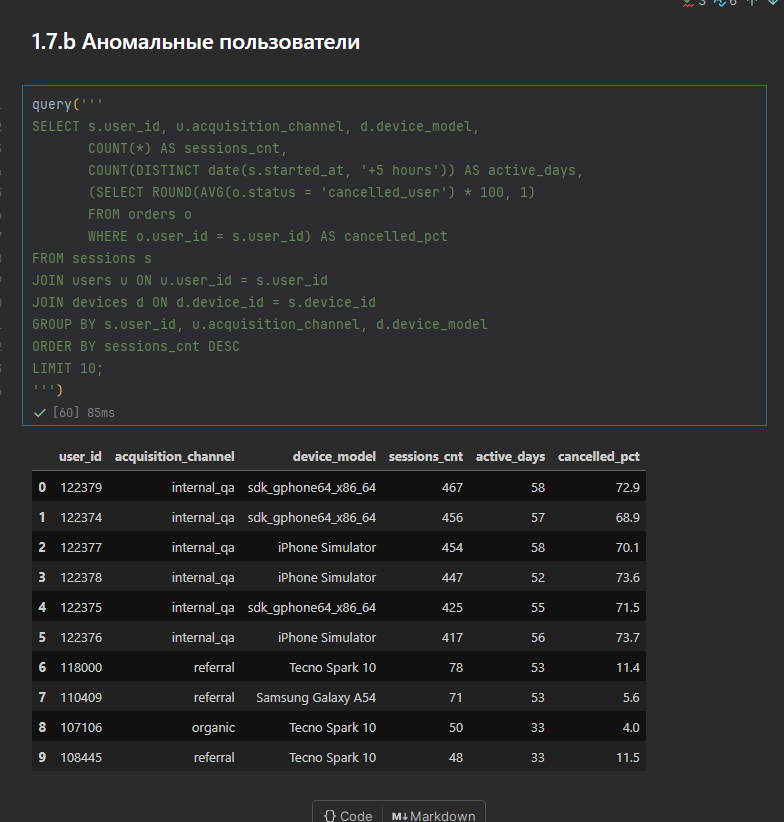

## <u>1.8 Чистый слой данных</u>
###### Зачем? Получилось 8 решений по очистке. Если повторять их в каждом из ~40 запросов, где-нибудь одно обязательно забудется, и цифры в отчёте перестанут сходиться. Поэтому очищаем один раз, создаём таблицы с суффиксом _c (clean), и все этапы 2–4 работают только с ними.

## Найденные проблемы качества данных

| Проблема | Масштаб                | Решение                             | На что повлияло бы |
|---|------------------------|-------------------------------------|---|
| Время в UTC | все таблицы            | `datetime(x, '+5 hours')`           | пики, DAU, когорты сдвинуты на 5 часов |
| Тестировщики | 6 человек, 5 % заказов | исключить                           | отмены, воронки |
| Дубли событий | 1,2 %                  | оставить одну копию                 | заказы по событиям |
| Сбитые часы телефона | 53 устройства          | время сессии или сервера            | даты событий |
| Невозможная длительность | 865 показов            | длительность → `NULL`               | время на экранах |
| Написание городов | 584 пользователя       | `CASE`-нормализация                 | доли городов |
| Год рождения 1900 | 33 пользователя        | -> `NULL`                           | возраст |
| Оборванные сессии | ~ 1 %                  | оставить, исключить из длительности | падения приложения |

In [19]:
execute('''
-- 1. Пользователи: без тестировщиков, города нормализованы, 1900 -> NULL, время UTC+5
DROP TABLE IF EXISTS temp.users_c;
CREATE TEMP TABLE users_c AS
SELECT user_id,
       datetime(registered_at, '+5 hours') AS registered_at,
       CASE
            WHEN city IN ('Ташкент', 'Tashkent', 'г. Ташкент', 'ташкент') THEN 'Ташкент'
            WHEN city IN ('Самарканд', 'Samarkand')                       THEN 'Самарканд'
            WHEN city IN ('Фергана', 'Fergana')                           THEN 'Фергана'
            WHEN city IN ('Андижан', 'Andijan')                           THEN 'Андижан'
            WHEN city IN ('Бухара', 'Bukhara')                            THEN 'Бухара'
            ELSE city
       END AS city,
       CASE
            WHEN birth_year BETWEEN 1930 AND 2012 THEN birth_year
       END AS birth_year,
       acquisition_channel AS channel
FROM users
WHERE acquisition_channel <> 'internal_qa';

-- 2. Устройства только "чистых" пользователей
DROP TABLE IF EXISTS temp.devices_c;
CREATE TEMP TABLE devices_c AS
SELECT device_id, d.user_id, d.platform, d.device_model, d.os_version,
       datetime(d.first_seen_at, '+5 hours') AS first_seen_at
FROM devices d
WHERE d.user_id IN (SELECT user_id FROM users_c);

-- 3. Сессии: время UTC+5, оборванные (ended_at = NULL) оставляю
DROP TABLE IF EXISTS temp.sessions_c;
CREATE TEMP TABLE sessions_c AS
SELECT s.session_id, s.user_id, s.device_id,
       datetime(s.started_at, '+5 hours') AS started_at,
       datetime(s.ended_at, '+5 hours') AS ended_at,
       s.app_version, s.network_type
FROM sessions s
WHERE s.user_id IN (SELECT user_id FROM users_c);

-- создаю индекс, то есть "оглавление" для быстрого поиска по колонке `session_id`
 CREATE INDEX temp.ix_sessions_c_session ON sessions_c(session_id);

 -- 4. Просмотры экранов: невозможная длительность -> NULL, строки сохраняю
 DROP TABLE IF EXISTS temp.screen_views_c;
 CREATE TEMP TABLE screen_views_c AS
 SELECT sv.view_id, sv.session_id, sv.screen_name,
        datetime(sv.entered_at, '+5 hours') AS entered_at,
        CASE
            WHEN sv.duration_ms BETWEEN 0 AND 86400000 THEN sv.duration_ms
        END AS duration_ms
 FROM screen_views sv
 WHERE sv.session_id IN (SELECT session_id FROM sessions_c);
 CREATE INDEX temp.ix_screen_views_c_session ON screen_views_c(session_id);

 -- 5. События: без дублей, время сервера (не телефона), UTC+5
 DROP TABLE IF EXISTS temp.events_c;
 CREATE TEMP TABLE events_c AS
 SELECT event_id, session_id, user_id, device_id,
        datetime(server_ts, '+5 hours') AS event_ts,
        event_name, screen_name, event_params
 FROM(
      SELECT e.*,
             ROW_NUMBER() OVER (
                  PARTITION BY e.session_id, e.event_name, e.client_ts,
                  COALESCE(e.event_params, '')
                  ORDER BY e.server_ts, e.event_id
             ) AS rn
      FROM events e
 ) AS numbered
 WHERE rn = 1 AND session_id IN (SELECT session_id FROM sessions_c);
 CREATE INDEX temp.ix_events_c_session ON events_c(session_id);

 -- 6. Заказы "чистых" сессий, UTC+5
 DROP TABLE IF EXISTS temp.orders_c;
 CREATE TEMP TABLE orders_c AS
 SELECT o.order_id, o.user_id, o.session_id, o.service, o.tariff,
       datetime(o.created_at, '+5 hours') AS created_at,
       o.status, o.price_uzs, o.distance_km, o.wait_time_sec,
       o.payment_method, o.promo_applied, o.rating
FROM orders o
WHERE o.session_id IN (SELECT session_id FROM sessions_c);

-- 7. A/B-назначения без тестировщиков, UTC+5
DROP TABLE IF EXISTS temp.ab_c;
CREATE TEMP TABLE ab_c AS
SELECT a.user_id, a.experiment, a.variant,
       datetime(a.assigned_at, '+5 hours') AS assigned_at
FROM ab_assignments a
WHERE a.user_id IN (SELECT user_id FROM users_c);
''')

#### Так как вывода нет: выведу старые и исправленные таблицы с подсчетом строк. Ориентируюсь на `users`. Их должно остаться на 6 меньше

In [20]:
query('''
SELECT 'users'                    AS tbl,
(SELECT COUNT(*) FROM users)      AS before_cnt,
(SELECT COUNT(*) FROM users_c)    AS after_cnt
UNION ALL
SELECT 'sessions',
(SELECT COUNT(*) FROM sessions),
(SELECT COUNT(*) FROM sessions_c)
UNION ALL
SELECT 'events',
(SELECT COUNT(*) FROM events),
(SELECT COUNT(*) FROM events_c)
UNION ALL
SELECT 'orders',
(SELECT COUNT(*) FROM orders),
(SELECT COUNT(*) FROM orders_c)
UNION ALL
SELECT 'screen_views',
(SELECT COUNT(*) FROM screen_views),
(SELECT COUNT(*) FROM screen_views_c)

''')

,tbl,before_cnt,after_cnt
0,users,9006,9000
1,sessions,49191,46525
2,events,270273,253904
3,orders,21954,20829
4,screen_views,286078,272977


#### Как видно из таблицы пользователи сократились на 6 человек
Результат очистки: пользователей 9 006 -> 9 000, сессий 49 191 -> 46 525, событий 270 273 -> 253 904, заказов 21 954 -> 20 829.

---

---

# <u>Этап 2. Аудитория и активность</u>

### Цель: описать кто пользуется приложением и как часто.

## <u>2.1 DAU, WAU, MAU</u>
###### Зачем? Узнать сколько людей пользуется приложением в день/неделю/месяц
Идея: все 3 метрики - это COUNT(DISTINCT user_id) - уникальные значения без повторов, только за окно разной длины: 1, 7 и 30 дней. MAU **нельзя** получить суммой DAU: человек, заходивший 10 раз за месяц, посчитался бы 10 раз

In [21]:
activity = query('''
WITH ud AS (
      -- пары "пользователь - день" без повторов
      SELECT DISTINCT user_id, date(started_at) AS day
      FROM sessions_c
),
days AS (
    SELECT DISTINCT day FROM ud
)
SELECT d.day,
       COUNT(DISTINCT CASE WHEN ud.day = d.day THEN ud.user_id END) AS dau,
       COUNT(DISTINCT CASE WHEN ud.day > date(d.day, '-7 day') THEN ud.user_id END) AS wau,
       COUNT(DISTINCT ud.user_id ) AS mau
FROM days d
-- JOIN по промежутку ("скользящее окно") 30 дней от проверяемой даты
JOIN ud ON ud.day BETWEEN date(d.day, '-29 day') AND d.day
GROUP BY d.day
ORDER BY d.day
''')
activity

,day,dau,wau,mau
0,2026-06-01,118,118,118
1,2026-06-02,121,229,229
2,2026-06-03,147,355,355
3,2026-06-04,145,468,468
4,2026-06-05,173,598,598
5,2026-06-06,152,699,699
6,2026-06-07,154,799,799
7,2026-06-08,163,821,892
8,2026-06-09,199,869,1005
9,2026-06-10,183,878,1106


In [22]:
activity['day'] = pd.to_datetime(activity['day'])
# сглаживание: среднее за 7 дней
activity['dau_7d'] = activity['dau'].rolling(7).mean()
# какая доля пользователей в месяц заходит в приложение в обычный день
activity['stickiness'] = activity['dau'] / activity['mau']

# Отсеиваю даты до 30.06.2026, чтобы окно MAU было всегда "полным".
# Если этого не сделать, то окно сдвинется "левее" на май, который не входит в рассматриваемый период
full_window = activity[activity['day'] >= '2026-06-30']

# среднее за первую неделю
dau_first = activity['dau'].head(7).mean()
# среднее за последнюю неделю
dau_last = activity['dau'].tail(7).mean()
print(f'DAU, первая неделя (среднее):    {dau_first:.0f}')
print(f'DAU, последняя неделя (среднее): {dau_last:.0f}')
print(f'Рост DAU:                        в {dau_last / dau_first:.1f} раза')
print(f'MAU на 31.08:                    {activity["mau"].iloc[-1]}')
print(f'Stickiness (с 30.06, среднее):   {full_window["stickiness"].mean() * 100:.1f} %')


DAU, первая неделя (среднее):    144
DAU, последняя неделя (среднее): 561
Рост DAU:                        в 3.9 раза
MAU на 31.08:                    6104
Stickiness (с 30.06, среднее):   9.5 %


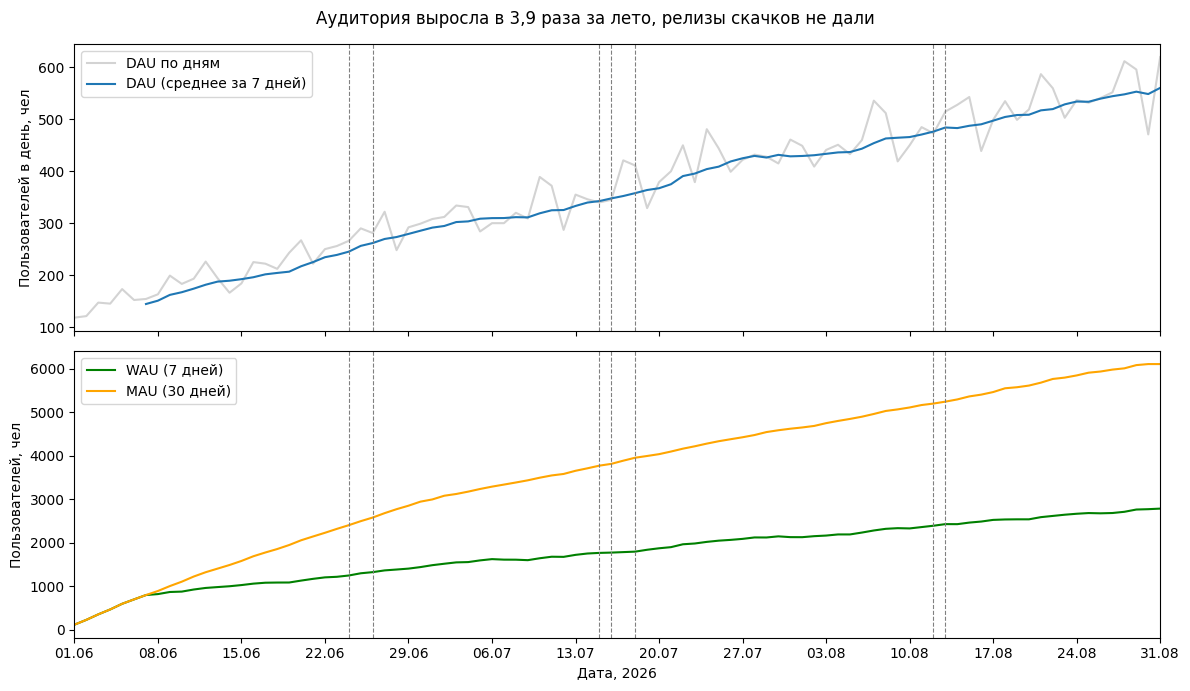

In [23]:
FIG_DIR = Path.cwd().parent / 'reports' / 'figures' # путь к папке с графиками из корня проекта

releases = query('SELECT platform, app_version, released_at FROM app_releases')
releases['released_at'] = pd.to_datetime(releases['released_at'])

fig, (ax_dau, ax_mau) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

# верхний график: DAU
ax_dau.plot(activity['day'], activity['dau'], color='lightgrey', label='DAU по дням')
ax_dau.plot(activity['day'], activity['dau_7d'], label='DAU (среднее за 7 дней)')
ax_dau.set_ylabel('Пользователей в день, чел')

# нижний график: WAU и MAU
ax_mau.plot(activity['day'], activity['wau'], label='WAU (7 дней)', color='green')
ax_mau.plot(activity['day'], activity['mau'], label='MAU (30 дней)', color='orange')
ax_mau.set_ylabel('Пользователей, чел')
ax_mau.set_xlabel('Дата, 2026')
# Убираю год из вывода дат, чтобы не забивать график и расставляю даты по понедельникам
ax_mau.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
ax_mau.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
# Вставляю в график отметки с датами релизов для обоих графиков
for ax in (ax_dau, ax_mau):
    for released in releases['released_at']:
      ax.axvline(released, color='grey', linestyle='--', linewidth=0.8)
    ax.legend(loc='upper left')

ax_mau.set_xlim(activity['day'].min(), activity['day'].max())
fig.suptitle('Аудитория выросла в 3,9 раза за лето, релизы скачков не дали')
fig.tight_layout()
fig.savefig(FIG_DIR / '01_dau_mau.png', dpi=300, bbox_inches='tight')
plt.show()

#### Вывод по графику:
   * **Рост ровный и не связан с релизами:** вертикальные линии релизов не совпадают со скачками. Значит рост дает привлечение пользователей, а не новые функции;
   * **Stickiness 9,5 % - это около 3 дней в месяц** (0,095 * 30). Для такси и доставки это нормально: ими пользуются "по поводу", а не каждый день, как мессенджером;
   * **Stickiness считаем только с 30.06** так как данных до 1 июня нет, поэтому в июне MAU неполный (окно в 30 дней еще не заполнено) и Stickiness получилась бы завышенной. Это **краевой эффект** - он еще будет в проекте

**Что дальше?** Раз аудитория растет на ~ 10 % в неделю, сравнивать июнь с августом напрямую опасно: многие метрики будут расти только изз-за роста аудитории. Дальше смотрим **доли и конверсии**, а не абсолютные числа.

---

## <u>2.2 Когда пользуются приложением</u>
#### Зачем? Чтобы знать когда пользуются приложением, когда отправлять пуши и когда пик нагрузки.

**Идея:** Такси, скорее всего нужны по дороге с работы и на работу, еда - на обед и ужин. Считаем это по заказам, а не по сессиям: заказ - более надежный признак намерения

In [24]:
hours = query('''
SELECT service,
       -- CAST - преобразование типа
       -- strftime('%w', ...) - возвращает день недели в INT, но 0 = воскресенье
       -- (+ 6) % 7 - сдвигает так, чтобы 0 - был понедельником
       -- strftime('%H', ...) - возвращает час суток
       (CAST(strftime('%w', created_at) AS INTEGER) + 6) % 7 AS dow,
       CAST(strftime('%H', created_at) AS INTEGER)           AS hour,
       COUNT(*)                                              AS orders_cnt
FROM orders_c
GROUP BY service, dow, hour;
''')

#### Построение тепловой карты
###### Почему тепловая карта? Данные двумерные: день недели * час. Таблица была бы нечитаема, а цвет сразу показывает "горячие" места. Нормирую каждую карту на сумму заказов сервиса: иначе такси забьет цветом еду и самокаты

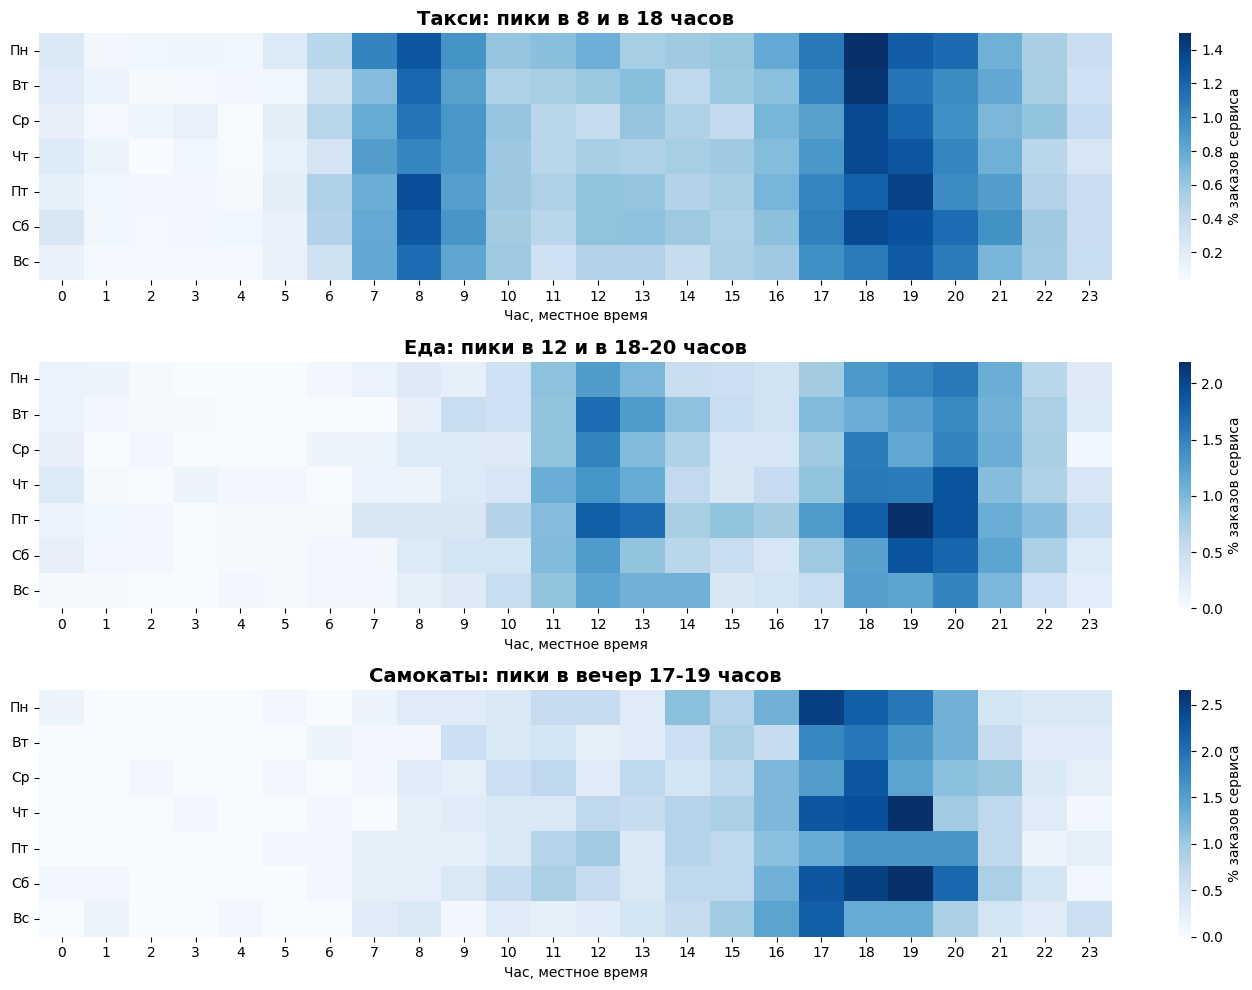

In [35]:
# доля от всех заказов сервиса, иначе такси "забьет" цветом еду и самокаты
hours['share_pct'] = (
        hours['orders_cnt'] / hours.groupby('service')['orders_cnt'].transform('sum') * 100)

day_names = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
titles = {
    'taxi': 'Такси: пики в 8 и в 18 часов',
    'food': 'Еда: пики в 12 и в 18-20 часов',
    'scooter': 'Самокаты: пики в вечер 17-19 часов',
}

food_dow = hours[hours['service'] == 'food'].groupby('dow')['orders_cnt'].sum()
food_dow / food_dow.mean() # ПТ - 1,30 %
fig, axes = plt.subplots(3, 1, figsize=(14, 10))

# zip сшивает 2 списка попарно
# .reindex(undex=range(7), columns=range(24)) - говорит, что должно быть ровно 0..6 строк
# и 0..23 колонки, в этом порядке - если значения нет - будет NULL
# .fillna(0) заменяет все получившиеся NULL на 0
for ax, service in zip(axes, ['taxi', 'food', 'scooter']):
    pivot = (hours[hours['service'] == service]
        .pivot(index='dow', columns='hour', values='share_pct')
        .reindex(index=range(7), columns=range(24))
        .fillna(0)
    )
    sns.heatmap(pivot, ax=ax, cmap='Blues', cbar_kws={'label': '% заказов сервиса'})
    # Подставляю названия дней вместо чисел
    ax.set_yticklabels(day_names, rotation=0)
    ax.set_title(f'{titles[service]}', fontsize=14, fontweight='bold')
    ax.set_xlabel('Час, местное время')
    ax.set_ylabel('')

fig.tight_layout()
fig.savefig(FIG_DIR / '02_heatmap_orders.png', dpi=300, bbox_inches='tight')
plt.show()


#### Вывод по таблице:
* **Такси - пики в 8 и в 18 часов** по будням и выходным. Это дорога на работу и домой
* **Еда - пики в 12 и в 18-20 часов** - это обед и ужин. В пятницу самый "вкусный день" - на 30 % больше заказов еды, чем в средний день
* **Самокаты - вечер 17-19 часов** - вероятно, когда жара спадает

Пики совпадают с "логическими" часами - косвенная проверка, что время переведено правильно
**Что дальше?** Проверить 8-9 и 18-19 на нехватку машин в часы пик